
# Phase 10C — Spectral analysis of the real Phase-8B 6-bit surface

This notebook is wired to the Phase-8B export surface:

- 4 real queries
- 64 masks per query
- \(6\) evidence bits because \(2^6=64\)
- primary signal \(F(S)=\) `quality/token_f1`

Unlike the older 4-bit Phase-10 run, this notebook analyzes the **new non-flat Phase-8B signal**.

It reports:

\[
\text{Walsh energy by order}
\]

both including and excluding the DC component,

\[
f^\top Lf
\]

on the 6-cube,

one-bit sensitivities,

and graph heat-flow roughness for non-flat tasks only.


In [1]:

from pathlib import Path
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_PATH = "phase8b_subset_surface_quality.csv"

df = pd.read_csv(DATA_PATH)
display(df.head())

N_STATES = int(df["mask"].max()) + 1
N_BITS = int(round(math.log2(N_STATES)))

assert 2**N_BITS == N_STATES
print("N_BITS:", N_BITS)
print("N_STATES:", N_STATES)
print("queries:", df["query_id"].nunique())


,provider,query_id,mask,F,n_repeats,p_exact
0,local,5a855b5c5542997b5ce3ffeb,0,0.00,1,0.0
1,local,5a855b5c5542997b5ce3ffeb,1,0.00,1,0.0
2,local,5a855b5c5542997b5ce3ffeb,2,0.00,1,0.0
3,local,5a855b5c5542997b5ce3ffeb,3,0.25,1,0.0
4,local,5a855b5c5542997b5ce3ffeb,4,0.00,1,0.0


N_BITS: 6
N_STATES: 64
queries: 4


In [2]:

def fwht(a):
    a = np.asarray(a, dtype=float).copy()
    h = 1
    n = len(a)
    while h < n:
        for i in range(0, n, 2*h):
            x = a[i:i+h].copy()
            y = a[i+h:i+2*h].copy()
            a[i:i+h] = x + y
            a[i+h:i+2*h] = x - y
        h *= 2
    return a

def popcount(x):
    return int(x).bit_count()

def walsh_energy_by_order(f, d=N_BITS):
    coeff = fwht(np.asarray(f, float)) / len(f)
    rows = []
    for order in range(d + 1):
        idx = [i for i in range(2**d) if popcount(i) == order]
        rows.append({
            "order": order,
            "energy": float(np.sum(coeff[idx]**2)),
            "abs_mass": float(np.sum(np.abs(coeff[idx]))),
        })
    return pd.DataFrame(rows), coeff


In [3]:

# Build 6-cube Laplacian.
def hypercube_laplacian(d):
    n = 2**d
    A = np.zeros((n, n), dtype=float)
    for x in range(n):
        for bit in range(d):
            A[x, x ^ (1 << bit)] = 1.0
    return np.diag(A.sum(axis=1)) - A

L = hypercube_laplacian(N_BITS)
eigvals, eigvecs = np.linalg.eigh(L)

expected = []
for k in range(N_BITS + 1):
    expected.extend([2*k] * math.comb(N_BITS, k))

print("matches Q_6 theory:", np.allclose(eigvals, expected))
print("eigenvalue multiplicities:")
print(pd.Series(np.round(eigvals, 10)).value_counts().sort_index())


matches Q_6 theory: True
eigenvalue multiplicities:
0.0      1
2.0      6
4.0     15
6.0     20
8.0     15
10.0     6
12.0     1
Name: count, dtype: int64


In [4]:

def edge_sensitivity(f):
    f = np.asarray(f, float)
    rows = []
    for bit in range(N_BITS):
        d = []
        for x in range(N_STATES):
            if ((x >> bit) & 1) == 0:
                d.append(f[x | (1 << bit)] - f[x])
        d = np.asarray(d)
        rows.append({
            "bit": bit,
            "mean_signed": float(d.mean()),
            "mean_abs": float(np.abs(d).mean()),
            "rms": float(np.sqrt(np.mean(d**2))),
        })
    return pd.DataFrame(rows)

def heat_flow(f, t):
    f = np.asarray(f, float)
    return eigvecs @ (np.exp(-t * eigvals) * (eigvecs.T @ f))

def roughness(f):
    f = np.asarray(f, float)
    return float(f @ L @ f)



## Per-query diagnostics

Two spectral normalizations are useful:

1. **total fraction**, including order 0;
2. **interaction fraction**, conditioned on non-DC energy:

\[
\frac{E_k}{\sum_{j\ge1}E_j},\qquad k\ge1.
\]

The second tells us how the *variation across masks* is distributed across interaction orders.


In [5]:

energy_rows = []
sensitivity_rows = []
summary_rows = []

for query_id, g in df.groupby("query_id"):
    g = g.sort_values("mask")
    f = g["F"].to_numpy(float)

    e, coeff = walsh_energy_by_order(f)
    total = float(e["energy"].sum())
    non_dc = float(e.loc[e["order"] > 0, "energy"].sum())

    e["query_id"] = query_id
    e["total_energy_fraction"] = np.where(
        total > 1e-15, e["energy"] / total, np.nan
    )
    e["non_dc_fraction"] = np.where(
        (e["order"] > 0) & (non_dc > 1e-15),
        e["energy"] / non_dc,
        np.nan,
    )
    energy_rows.append(e)

    s = edge_sensitivity(f)
    s["query_id"] = query_id
    sensitivity_rows.append(s)

    summary_rows.append({
        "query_id": query_id,
        "min_F": float(f.min()),
        "max_F": float(f.max()),
        "mean_F": float(f.mean()),
        "std_F": float(f.std(ddof=0)),
        "n_unique_F": int(len(np.unique(np.round(f, 12)))),
        "F_empty": float(f[0]),
        "F_full": float(f[-1]),
        "best_mask": int(np.argmax(f)),
        "best_F": float(np.max(f)),
        "laplacian_energy": roughness(f),
        "non_dc_energy": non_dc,
    })

energy = pd.concat(energy_rows, ignore_index=True)
sens = pd.concat(sensitivity_rows, ignore_index=True)
summary = pd.DataFrame(summary_rows)

display(summary)
display(energy)
display(sens)

summary.to_csv("phase10c_query_summary.csv", index=False)
energy.to_csv("phase10c_walsh_energy.csv", index=False)
sens.to_csv("phase10c_bit_sensitivity.csv", index=False)


,query_id,min_F,max_F,mean_F,std_F,n_unique_F,F_empty,F_full,best_mask,best_F,laplacian_energy,non_dc_energy
0,5a855b5c5542997b5ce3ffeb,0.0,0.444444,0.14434,0.174320,13,0.0,0.0,23,0.444444,8.176706,0.030387
1,5a860aa6554299211dda2a45,0.0,1.000000,0.57224,0.344430,4,0.0,0.0,2,1.000000,38.479676,0.118632
2,5a90b1a15542990a984936ab,0.0,1.000000,0.03125,0.173993,2,0.0,0.0,16,1.000000,10.000000,0.030273
3,5abcd77755429965836004ce,0.0,0.000000,0.00000,0.000000,1,0.0,0.0,0,0.000000,0.000000,0.000000


,order,energy,abs_mass,query_id,total_energy_fraction,non_dc_fraction
0,0,0.020834,0.144340,5a855b5c5542997b5ce3ffeb,0.406745,NaN
1,1,0.014894,0.220966,5a855b5c5542997b5ce3ffeb,0.290772,0.490130
2,2,0.003781,0.195298,5a855b5c5542997b5ce3ffeb,0.073815,0.124423
3,3,0.006496,0.290894,5a855b5c5542997b5ce3ffeb,0.126824,0.213777
4,4,0.004229,0.195567,5a855b5c5542997b5ce3ffeb,0.082563,0.139170
5,5,0.000905,0.063534,5a855b5c5542997b5ce3ffeb,0.017664,0.029775
6,6,0.000083,0.009099,5a855b5c5542997b5ce3ffeb,0.001616,0.002725
7,0,0.327459,0.572240,5a860aa6554299211dda2a45,0.734063,NaN
8,1,0.037125,0.357143,5a860aa6554299211dda2a45,0.083222,0.312938
9,2,0.028276,0.556006,5a860aa6554299211dda2a45,0.063386,0.238350


,bit,mean_signed,mean_abs,rms,query_id
0,0,0.213609,0.228351,0.281647,5a855b5c5542997b5ce3ffeb
1,1,0.062245,0.120755,0.197680,5a855b5c5542997b5ce3ffeb
2,2,0.022536,0.092303,0.162645,5a855b5c5542997b5ce3ffeb
3,3,0.008112,0.078754,0.142916,5a855b5c5542997b5ce3ffeb
4,4,0.054921,0.127696,0.202440,5a855b5c5542997b5ce3ffeb
5,5,0.080508,0.152045,0.221944,5a855b5c5542997b5ce3ffeb
6,0,0.082792,0.345779,0.460581,5a860aa6554299211dda2a45
7,1,-0.038961,0.237825,0.392132,5a860aa6554299211dda2a45
8,2,-0.012175,0.266234,0.454940,5a860aa6554299211dda2a45
9,3,-0.311688,0.374188,0.529519,5a860aa6554299211dda2a45


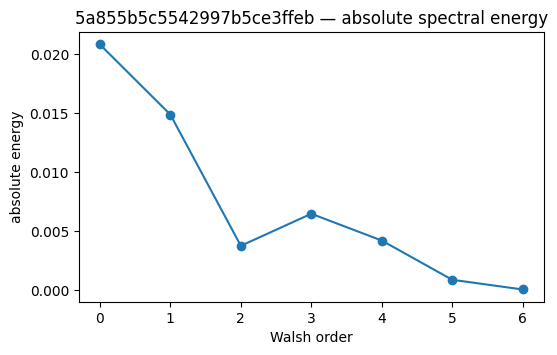

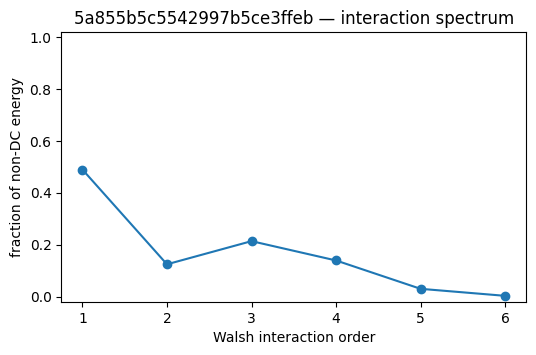

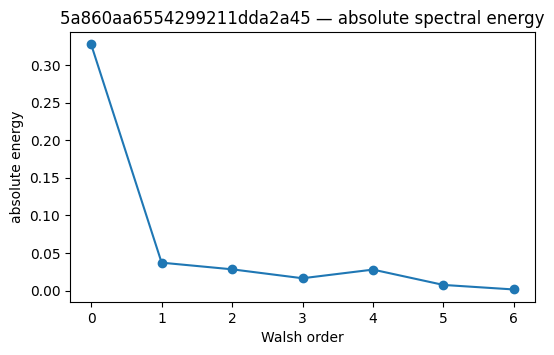

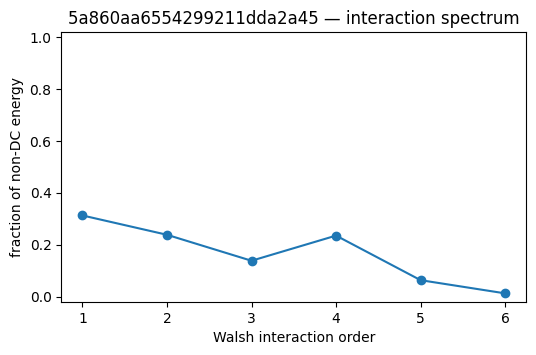

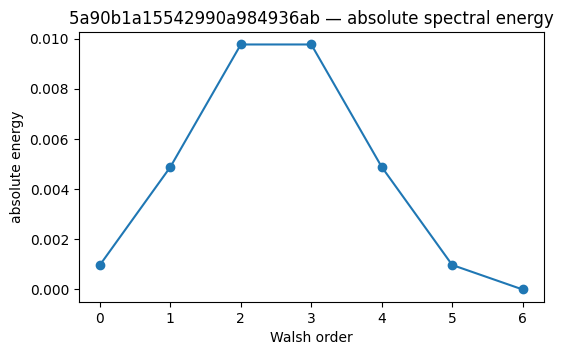

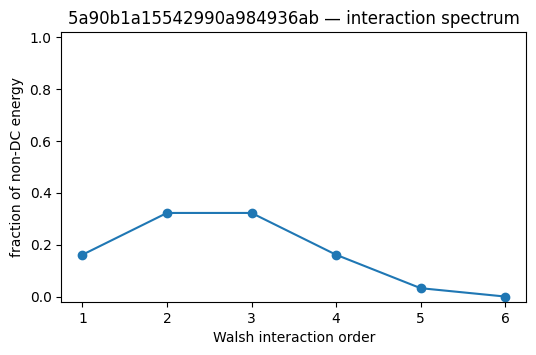

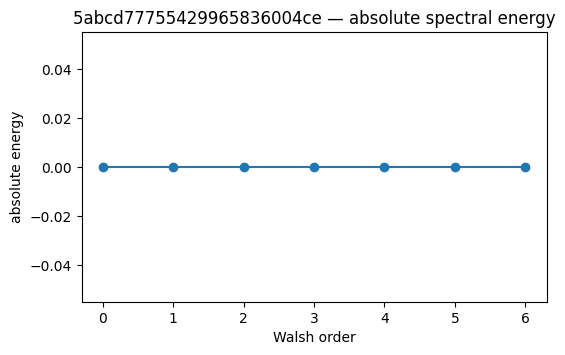

In [6]:

# Spectral plots.
for query_id, g in energy.groupby("query_id"):
    plt.figure(figsize=(6,3.5))
    plt.plot(g["order"], g["energy"], marker="o")
    plt.xlabel("Walsh order")
    plt.ylabel("absolute energy")
    plt.title(f"{query_id} — absolute spectral energy")
    plt.show()

    ng = g[g["order"] > 0]
    if ng["non_dc_fraction"].notna().any():
        plt.figure(figsize=(6,3.5))
        plt.plot(ng["order"], ng["non_dc_fraction"], marker="o")
        plt.ylim(-0.02, 1.02)
        plt.xlabel("Walsh interaction order")
        plt.ylabel("fraction of non-DC energy")
        plt.title(f"{query_id} — interaction spectrum")
        plt.show()


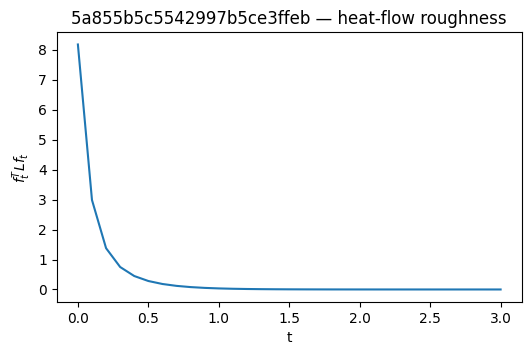

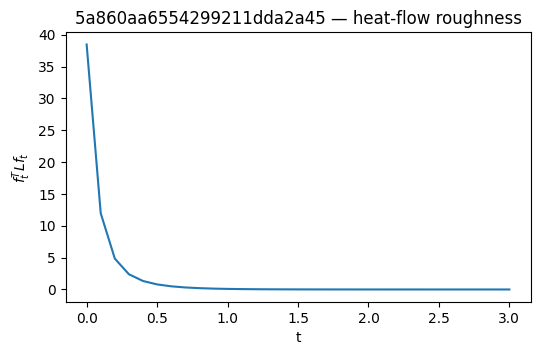

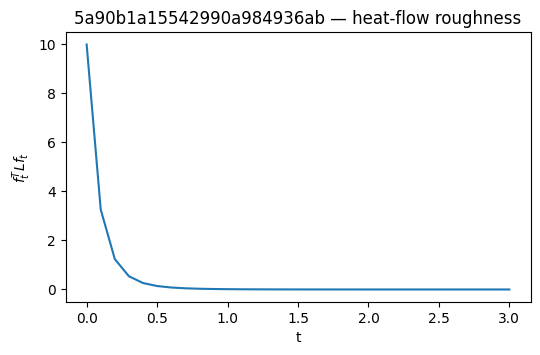

5abcd77755429965836004ce flat -> heat-flow plot skipped


In [7]:

# Heat-flow only for non-flat tasks.
ts = np.linspace(0, 3, 31)

for query_id, g in df.groupby("query_id"):
    g = g.sort_values("mask")
    f = g["F"].to_numpy(float)

    if np.std(f, ddof=0) < 1e-12:
        print(query_id, "flat -> heat-flow plot skipped")
        continue

    rough = [roughness(heat_flow(f, t)) for t in ts]

    plt.figure(figsize=(6,3.5))
    plt.plot(ts, rough)
    plt.xlabel("t")
    plt.ylabel(r"$f_t^T L f_t$")
    plt.title(f"{query_id} — heat-flow roughness")
    plt.show()



## Interpretation

A useful signal is not required to be monotone with the number of evidence cards.

Indeed, if adding distractors causes context interference, one may observe

\[
F(S\cup\{i\}) < F(S).
\]

That is a real feature of the subset surface, not an error.

Because there is currently only one repeat per mask, treat fine-grained high-order structure cautiously until repeated runs establish that it is stable.
